### 文档切分：为什么以及如何切分？
---
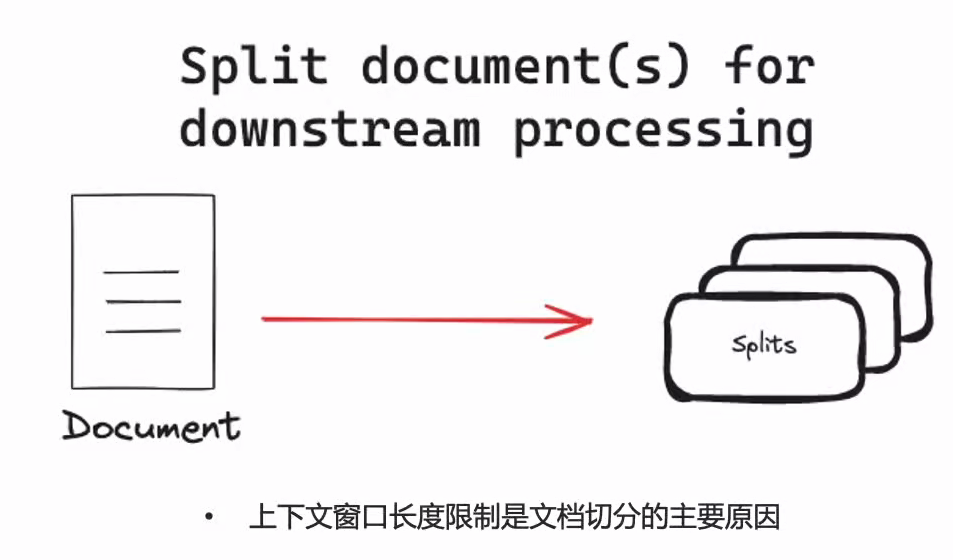
 
* 如何基于长度切分
* 如何基于文本架构进行切分
* 如何基于文档进行切分
* 智能：基于语义进行切分

### 长度切分
---

In [1]:
! pip install langchain-text-splitters


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from langchain_classic.document_loaders import PyPDFLoader
from langchain_text_splitters import CharacterTextSplitter

file_path = "math.pdf"

loader = PyPDFLoader(file_path)
pages = []
async for page in loader.alazy_load():
    pages.append(page)

text_splitter = CharacterTextSplitter.from_tiktoken_encoder(
    encoding_name="cl100k_base", chunk_size=50, chunk_overlap=0
)
texts = text_splitter.split_text(pages[1].page_content)
print(texts)
docs = text_splitter.create_documents([pages[2].page_content,pages[3].page_content])
print(docs)

['2 \n一、函数与极限 \n1、集合的概念 \n一般地我们把研究对象统称为元素，把一些元素组成的总体叫集合（简称集）。集合具有确定性（给\n定集合的元素必须是确定的）和互异性（给定集合中的元素是互不相同的）。比如“身材较高的人”不能\n构成集合，因为它的元素不是确定的。 \n我们通常用大字拉丁字母 A、B、C、……表示集合，用小写拉丁字母 a、b、c……表示集合中的元素。\n如果 a是集合 A中的元素，就说 a属于 A，记作：a∈A，否则就说 a 不属于 A，记作：a A。 \n⑴、全体非负整数组成的集合叫做非负整数集（或自然数集）。记作 N \n⑵、所有正整数组成的集合叫做正整数集。记作 N+或 N+。 \n⑶、全体整数组成的集合叫做整数集。记作 Z。 \n⑷、全体有理数组成的集合叫做有理数集。记作 Q。 \n⑸、全体实数组成的集合叫做实数集。记作 R。 \n集合的表示方法 \n⑴、列举法：把集合的元素一一列举出来，并用“｛｝”括起来表示集合 \n⑵、描述法：用集合所有元素的共同特征来表示集合。 \n集合间的基本关系 \n⑴、子集：一般地，对于两个集合 A、B，如果集合 A中的任意一个元素都是集合 B 的元素，我们就\n说 A、B有包含关系，称集合 A为集合 B 的子集，记作 A B（或 B A）。。 \n⑵相等：如何集合 A是集合 B的子集，且集合 B是集合 A的子集，此时集合 A中的元素与集合 B 中\n的元素完全一样，因此集合 A与集合 B相等，记作 A＝B。 \n⑶、真子集：如何集合A是集合 B的子集，但存在一个元素属于 B但不属于 A，我们称集合 A是集合\nB的真子集。 \n⑷、空集：我们把不含任何元素的集合叫做空集。记作 ，并规定，空集是任何集合的子集。 \n⑸、由上述集合之间的基本关系，可以得到下面的结论： \n①、任何一个集合是它本身的子集。即 A A \n②、对于集合 A、B、C，如果 A 是 B的子集，B是 C的子集，则 A 是 C的子集。 \n③、我们可以把相等的集合叫做“等集”，这样的话子集包括“真子集”和“等集”。 \n集合的基本运算 \n⑴、并集：一般地，由所有属于集合 A或属于集合 B的元素组成的集合称为 A 与 B 的并集。记作 A\n∪B。（在求并集时，它们的公共元素在并集中只能出现一次。） \n即 A∪B＝｛x|x∈A，或

### 基于文本架构
---

In [3]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
text_splitter = RecursiveCharacterTextSplitter(chunk_size=50, chunk_overlap=0)
texts = text_splitter.split_text(pages[1].page_content)
print(texts)

['2 \n一、函数与极限 \n1、集合的概念', '一般地我们把研究对象统称为元素，把一些元素组成的总体叫集合（简称集）。集合具有确定性（给', '定集合的元素必须是确定的）和互异性（给定集合中的元素是互不相同的）。比如“身材较高的人”不能', '构成集合，因为它的元素不是确定的。', '我们通常用大字拉丁字母 A、B、C、……表示集合，用小写拉丁字母 a、b、c……表示集合中的元素。', '如果 a是集合 A中的元素，就说 a属于 A，记作：a∈A，否则就说 a 不属于 A，记作：a', 'A。', '⑴、全体非负整数组成的集合叫做非负整数集（或自然数集）。记作 N', '⑵、所有正整数组成的集合叫做正整数集。记作 N+或 N+。', '⑶、全体整数组成的集合叫做整数集。记作 Z。 \n⑷、全体有理数组成的集合叫做有理数集。记作 Q。', '⑸、全体实数组成的集合叫做实数集。记作 R。 \n集合的表示方法', '⑴、列举法：把集合的元素一一列举出来，并用“｛｝”括起来表示集合', '⑵、描述法：用集合所有元素的共同特征来表示集合。 \n集合间的基本关系', '⑴、子集：一般地，对于两个集合 A、B，如果集合 A中的任意一个元素都是集合 B 的元素，我们就', '说 A、B有包含关系，称集合 A为集合 B 的子集，记作 A B（或 B A）。。', '⑵相等：如何集合 A是集合 B的子集，且集合 B是集合 A的子集，此时集合 A中的元素与集合 B', '中', '的元素完全一样，因此集合 A与集合 B相等，记作 A＝B。', '⑶、真子集：如何集合A是集合 B的子集，但存在一个元素属于 B但不属于 A，我们称集合 A是集合', 'B的真子集。', '⑷、空集：我们把不含任何元素的集合叫做空集。记作 ，并规定，空集是任何集合的子集。', '⑸、由上述集合之间的基本关系，可以得到下面的结论： \n①、任何一个集合是它本身的子集。即 A A', '②、对于集合 A、B、C，如果 A 是 B的子集，B是 C的子集，则 A 是 C的子集。', '③、我们可以把相等的集合叫做“等集”，这样的话子集包括“真子集”和“等集”。 \n集合的基本运算', '⑴、并集：一般地，由所有属于集合 A或属于集合 B的元素组成的集合称为 A 与 B 的并集。记作', 'A', '∪B。（在求并

### 基于文档架构
---
* markdown 根据标题拆分 （例如，#、##、###）
* JSON：按对象或数组元素拆分

In [4]:
! pip install -qU langchain-text-splitters


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


基于markdown格式进行拆分

In [9]:
from langchain_text_splitters import MarkdownHeaderTextSplitter

markdown_document = "# Foo \n\n ## Bar\n\nHi this is Jim\n\nHi this is Joe\n\n ### Boo \n\n Hi this is Lance \n\n ## Baz \n\nHi this is Molly"

headers_to_split_on = [
    ("#", "Header 1"),
    ("##", "Header 2"),
    ("###", "Header 3"),
]

markdown_spliter = MarkdownHeaderTextSplitter(headers_to_split_on)
md_header_splits = markdown_spliter.split_text(markdown_document)
md_header_splits

[Document(metadata={'Header 1': 'Foo', 'Header 2': 'Bar'}, page_content='Hi this is Jim  \nHi this is Joe'),
 Document(metadata={'Header 1': 'Foo', 'Header 2': 'Bar', 'Header 3': 'Boo'}, page_content='Hi this is Lance'),
 Document(metadata={'Header 1': 'Foo', 'Header 2': 'Baz'}, page_content='Hi this is Molly')]

基于JSON格式进行切分

In [17]:
import json
import requests
from langchain_text_splitters import RecursiveCharacterTextSplitter

# 1. 获取 JSON 数据 (此时 json_data 是一个 Python 字典)
json_data = requests.get("https://api.smith.langchain.com/openapi.json").json()

# 2. 将字典转换为格式化的 JSON 字符串 (indent=2 使其具有可读性)
json_str = json.dumps(json_data, indent=2)

# 3. 初始化文本分割器
splitter = RecursiveCharacterTextSplitter(
    chunk_size=300, 
    chunk_overlap=20,
    separators=["\n\n", "\n", " ", ""] 
)

# 4. 使用 split_text 方法分割字符串 (这部分你之前已经写对了)
json_chunks = splitter.split_text(json_str)

for i, chunk in enumerate(json_chunks[:3]):
    print(f"--- Chunk {i+1} (长度: {len(chunk)}) ---")
    print(chunk)
    print("=" * 50)


docs = splitter.create_documents(texts=[json_str])

print("\n--- 生成的 LangChain Documents ---")
for doc in docs[:3]:
    print(doc)
    print("-" * 50)

--- Chunk 1 (长度: 61) ---
{
  "openapi": "3.1.0",
  "info": {
    "title": "LangSmith",
--- Chunk 2 (长度: 260) ---
"description": "The LangSmith API is used to programmatically create and manage LangSmith resources.\n\n## Host\nhttps://api.smith.langchain.com\n\n## Authentication\nTo authenticate with the LangSmith API, set the `X-Api-Key` header\nto a valid [LangSmith API
--- Chunk 3 (长度: 105) ---
[LangSmith API key](https://docs.langchain.com/langsmith/create-account-api-key#create-an-api-key).\n\n",

--- 生成的 LangChain Documents ---
page_content='{
  "openapi": "3.1.0",
  "info": {
    "title": "LangSmith",'
--------------------------------------------------
page_content='"description": "The LangSmith API is used to programmatically create and manage LangSmith resources.\n\n## Host\nhttps://api.smith.langchain.com\n\n## Authentication\nTo authenticate with the LangSmith API, set the `X-Api-Key` header\nto a valid [LangSmith API'
--------------------------------------------------
page_c

### 基于语义切分
---

In [18]:
! pip install --quiet langchain_experimental langchain_openai


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
from langchain_experimental.text_splitter import SemanticChunker
from langchain_openai.embeddings import OpenAIEmbeddings

from dotenv import load_dotenv
import os

load_dotenv()

with open("meow.txt") as f:
    meow = f.read()

from langchain_experimental.text_splitter import SemanticChunker
from langchain_openai.embeddings import OpenAIEmbeddings

# 使用OpenAIEmbeddings进行向量化
embeddings=OpenAIEmbeddings(
    model="Qwen/Qwen3-Embedding-8B",
    openai_api_key=os.getenv("api_key"),
    openai_api_base=os.getenv("base_url")
)

text_splitter = SemanticChunker(embeddings)

docs = text_splitter.create_documents([meow])
print(docs[0].page_content)

meow meow馃惐 
 meow meow馃惐 
 meow 馃槏馃槏
